# Exercise: linear algebra with `numpy.linalg`

## Introduction

`numpy.linalg` provides the classical linear algebra tools: products, norms, determinants, inverses, linear system solvers, least-squares, eigenvalues...

The steps are:

1. Manipulate vectors and matrices: products, transpose, norm, determinant, with a 2D rotation as example
2. Solve linear systems with `inv`, `solve`, `lstsq` and `pinv` to recover the composition of a mixture from its absorption spectrum
3. Play with eigenvalues and eigenvectors (`eig`, `eigh`) to find the principal axes of a cloud of points

Useful documentation: https://numpy.org/doc/stable/reference/routines.linalg.html

## Part I: vectors and matrices

In [1]:
import numpy as np

In [2]:
%matplotlib widget
# This requires ipympl
# Or for non-interactive plots: %matplotlib inline

from matplotlib import pyplot as plt

### Matrix product

In numpy, a vector is a 1D array and a matrix is a 2D array.

In [3]:
v = np.array([1., 2., 3.])
M = np.array([[4., 1., 0.],
              [2., 3., 0.],
              [1., 1., 1.]])

Compute:

* `M * v` (element-wise product with broadcasting)
* `M @ v` (matrix-vector product, same as `np.dot(M, v)`)
* `v @ v` (dot product)

What is the difference between `M * v` and `M @ v`?

In [4]:
elementwise = M * v
product = M @ v
dot = v @ v
print("M * v =\n", elementwise)
print("M @ v =", product)
print("v @ v =", dot)

M * v =
 [[4. 2. 0.]
 [2. 6. 0.]
 [1. 2. 3.]]
M @ v = [6. 8. 6.]
v @ v = 14.0


### Transpose, norm, determinant, rank

Compute:

* the transpose of `M` (hint: `.T`)
* two ways of computing the norm of `v` (hint: `np.linalg.norm` is one), and check you get the same result with both.
* the determinant of `M` (hint: `np.linalg.det`)
* the rank of `M` (hint: `np.linalg.matrix_rank`)

In [6]:
M_transpose = M.T
v_norm_1 = np.linalg.norm(v)
v_norm_2 = np.sqrt(v@v)
M_det = np.linalg.det(M)
M_rank = np.linalg.matrix_rank(M)
print("transpose:\n", M_transpose)
print("norm:", v_norm_1, v_norm_2)
print("det:", M_det, "rank:", M_rank)

transpose:
 [[4. 2. 1.]
 [1. 3. 1.]
 [0. 0. 1.]]
norm: 3.7416573867739413 3.7416573867739413
det: 10.000000000000002 rank: 3


Build a matrix `S` whose third row is the sum of the first two rows of `M`.
What are its determinant and its rank?

In [7]:
S = M.copy()
S[2] = S[:2].sum(axis=0)
print("det:", np.linalg.det(S), "rank:", np.linalg.matrix_rank(S))

det: 0.0 rank: 2


Note: because of floating point rounding, the determinant of a singular matrix is often not exactly 0 but very small (try with `np.arange(1, 10).reshape(3, 3) / 10`).
Never compare floats with `==`, use `np.isclose` / `np.allclose` instead.

### A 2D rotation

The matrix of a rotation of angle $\theta$ in 2D is:

$$
R = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}
$$

Write a function `rotation(theta)` returning this matrix for an angle in radians.

In [8]:
def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],[np.sin(theta), np.cos(theta)]])

The points of a shape are stored as a `(2, N)` array: first row is x, second row is y.

Rotate the shape by 30° (hint: `np.radians`) with a single matrix product.

In [10]:
shape = np.array([[0., 2., 2., 1., 0., 0.],
                  [0., 0., 1., 2., 1., 0.]])

R = rotation(np.radians(30))
rotated = R @ shape

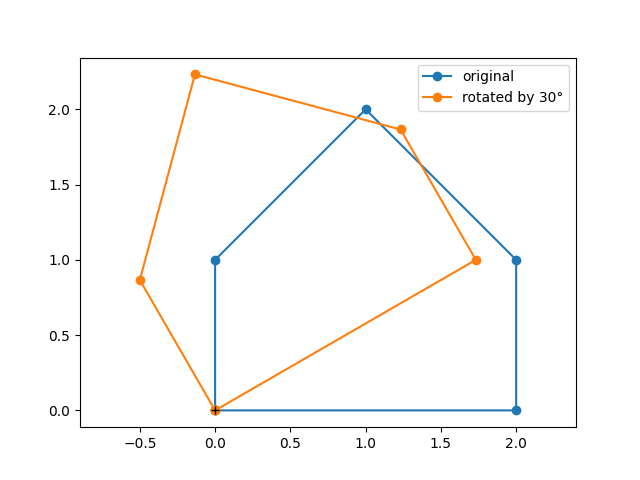

In [11]:
fig = plt.figure()
plt.plot(shape[0], shape[1], "o-", label="original")
plt.plot(rotated[0], rotated[1], "o-", label="rotated by 30°")
plt.plot(0, 0, "k+")
plt.axis("equal")
plt.legend()

A rotation preserves lengths and angles. Check with `np.allclose` that:

* $R^T R = I$ (hint: `np.eye`)
* $\det(R) = 1$
* the inverse of `R` (hint: `np.linalg.inv`) is its transpose, and is the rotation of angle $-\theta$
* the norm of each point (each column) is unchanged by the rotation (hint: `axis` argument of `np.linalg.norm`)

In [ ]:
# TODO

## Part II: solving linear systems

A solution contains 3 compounds with unknown concentrations $c_1, c_2, c_3$.
Each compound $j$ absorbs light at wavelength $\lambda$ with a known spectrum $\varepsilon_j(\lambda)$.

According to the Beer-Lambert law, the absorbance of the mixture is the sum of the contributions of each compound:

$$
A(\lambda) = \sum_j \varepsilon_j(\lambda) \, c_j
$$

Measured at several wavelengths $\lambda_i$, this is a linear system $E \, c = a$, with:

* `E`: the matrix of the spectra, of shape (number of wavelengths, 3), one column per compound
* `c`: the vector of the 3 unknown concentrations
* `a`: the measured absorbance at each wavelength

The goal is to recover `c` from `a`.

### The data

The following cell simulates the spectra of the compounds and a (noisy) measurement of the mixture.

In [12]:
wavelengths = np.linspace(400, 700, 61)  # in nm
centers = np.array([450, 530, 610])  # in nm

# One gaussian spectrum per compound, one column per compound
E = np.exp(-0.5 * ((wavelengths[:, np.newaxis] - centers) / 40) ** 2)

true_c = np.array([0.8, 0.3, 1.2])
rng = np.random.default_rng(seed=0)
absorbance = E @ true_c + rng.normal(scale=0.02, size=len(wavelengths))

print("E shape:", E.shape, "absorbance shape:", absorbance.shape)

E shape: (61, 3) absorbance shape: (61,)


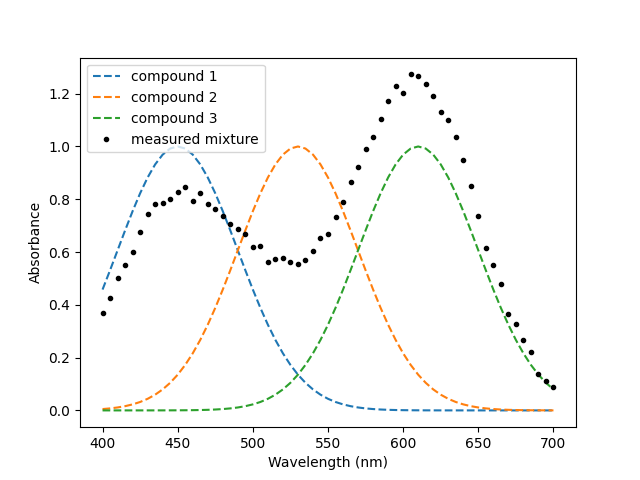

In [13]:
fig = plt.figure()
for j in range(3):
    plt.plot(wavelengths, E[:, j], "--", label=f"compound {j + 1}")
plt.plot(wavelengths, absorbance, "k.", label="measured mixture")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.legend()

### Square system: 3 equations, 3 unknowns

Keep only the measurements at the 3 wavelengths 450, 530 and 610 nm (hint: `np.isin`).

In [15]:
selection = np.isin(wavelengths,centers)
E3 = E[selection]
a3 = absorbance[selection]
print("E3 shape:", E3.shape, "a3 shape:", a3.shape)

E3 shape: (3, 3) a3 shape: (3,)


Solve $E_3 \, c = a_3$:

1. by computing the inverse of `E3` (hint: `np.linalg.inv`)
2. with `np.linalg.solve`

Check that both results are the same, and compare them with `true_c`.

In [17]:
c_inv = np.linalg.inv(E3) @ a3
c_solve = np.linalg.solve(E3,a3)
print("inv:  ", c_inv)
print("solve:", c_solve)
print("true: ", true_c)

inv:   [0.78988828 0.28253526 1.2292845 ]
solve: [0.78988828 0.28253526 1.2292845 ]
true:  [0.8 0.3 1.2]


Note: `solve` is faster and numerically more accurate than computing the inverse: prefer it when the inverse itself is not needed.

The result is not exactly `true_c` because the measurement is noisy, and only 3 measurements out of 61 were used...

### Overdetermined system: 61 equations, 3 unknowns

With all the wavelengths, there are more equations than unknowns: `E` is not square and has no inverse.
There is in general no exact solution, but we can find the `c` that minimizes the squared error $\| E \, c - a \|^2$: this is the **least-squares** solution.

Compute it:

1. with `np.linalg.lstsq` (use `rcond=None`), which returns a tuple: the solution is its first element
2. with the pseudo-inverse `np.linalg.pinv`
3. with the *normal equations*: $c = (E^T E)^{-1} E^T a$

In [21]:
c_lstsq = np.linalg.lstsq(E,absorbance) # TODO
c_pinv = np.linalg.pinv(E) @ absorbance
c_normal = (np.linalg.inv(E.T @ E) @ E.T) @ absorbance
print("lstsq: ", c_lstsq)
print("pinv:  ", c_pinv)
print("normal:", c_normal)
print("true:  ", true_c)

lstsq:  (array([0.79592422, 0.29536867, 1.21373349]), array([0.01684036]), np.int32(3), array([4.64478932, 3.70038532, 2.61097227]))
pinv:   [0.79592422 0.29536867 1.21373349]
normal: [0.79592422 0.29536867 1.21373349]
true:   [0.8 0.3 1.2]


Compute the error (norm of the difference with `true_c`) of the square-system solution and of the least-squares solution. Which one is better?

In [23]:
error_square = np.linalg.norm(c_inv - true_c)
error_lstsq = np.linalg.norm(c_lstsq[0] - true_c)
print("error square:", error_square, "error lstsq:", error_lstsq)

error square: 0.035564668163136796 error lstsq: 0.015055559234854604


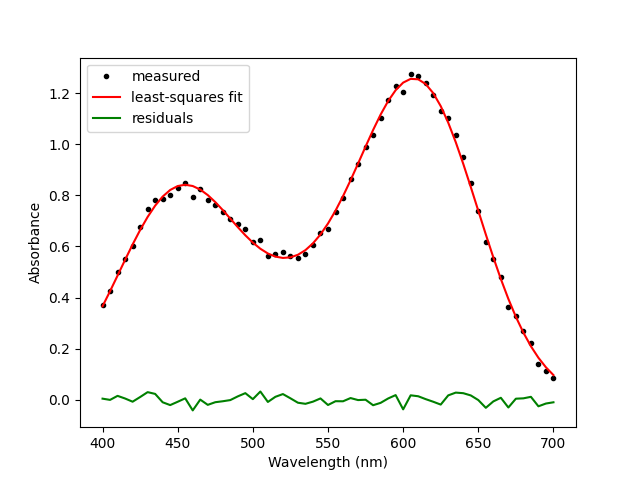

In [26]:
fig = plt.figure()
plt.plot(wavelengths, absorbance, "k.", label="measured")
plt.plot(wavelengths, E @ c_lstsq[0], "r", label="least-squares fit")
plt.plot(wavelengths, absorbance - E @ c_lstsq[0], "g", label="residuals")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorbance")
plt.legend()

### Underdetermined system: 2 equations, 3 unknowns

Now only the wavelengths 480 and 580 nm are measured: there are infinitely many solutions.

`np.linalg.pinv` (and `np.linalg.lstsq`) still return one: the solution with the **smallest norm**.

* Compute it and check that it does solve the 2 equations.
* Is it close to `true_c`?

In [ ]:
selection2 = # TODO
E2 = # TODO
a2 = # TODO
c_min_norm = # TODO
print("solution:", c_min_norm)
print("E2 @ c =", E2 @ c_min_norm, "a2 =", a2)
print("true:", true_c)

Note: `np.linalg.solve(E2, a2)` raises an error, try it!

### Bonus: ill-conditioned system

The *condition number* (`np.linalg.cond`) measures how much the errors on `a` can be amplified on the solution `c`.

Redo the least-squares fit with spectra centered at 520, 530 and 540 nm, which are very similar to each other.

* Compare the condition numbers of both `E` matrices.
* Compare the errors on `c`.

In [ ]:
E_close = # TODO
absorbance_close = E_close @ true_c + rng.normal(scale=0.02, size=len(wavelengths))
c_close = # TODO
print("cond E:", np.linalg.cond(E), "cond E_close:", np.linalg.cond(E_close))
print("solution:", c_close, "true:", true_c)

## Part III: eigenvalues and eigenvectors

An eigenvector $v$ of a square matrix $A$ is a non-zero vector whose direction is unchanged by $A$:

$$
A \, v = \lambda \, v
$$

where $\lambda$ is the associated eigenvalue.

### Eigenvalues of a matrix

Compute the eigenvalues and eigenvectors of `M` (hint: `np.linalg.eig`).

The eigenvectors are the **columns** of the returned matrix.
Check that $M \, v = \lambda \, v$ for each of them.

In [ ]:
eigenvalues, eigenvectors = # TODO
print("eigenvalues:", eigenvalues)
# TODO check

Check that:

* the product of the eigenvalues is the determinant of `M` (hint: `np.prod`)
* the sum of the eigenvalues is the trace of `M` (hint: `np.trace`)
* with $V$ the matrix of the eigenvectors and $D$ the diagonal matrix of the eigenvalues (hint: `np.diag`), $M = V D V^{-1}$

In [ ]:
# TODO

### Eigenvalues of a rotation

What are the eigenvalues of the 30° rotation matrix `R`? Why?

Compare them with $e^{\pm i \theta}$ (hint: `np.exp(1j * theta)`).

In [ ]:
# TODO

### Principal axes of a cloud of points

The following cell generates 500 points in 2D, stored as a `(2, 500)` array, spread along a tilted direction.

In [ ]:
rng = np.random.default_rng(seed=1)
points = rotation(np.radians(35)) @ (np.array([[3.], [0.8]]) * rng.normal(size=(2, 500)))
points += np.array([[5.], [2.]])

In [ ]:
fig = plt.figure()
plt.plot(points[0], points[1], ".", alpha=0.5)
plt.axis("equal")

The covariance matrix of the points (hint: `np.cov`) is a symmetric 2x2 matrix.
Its eigenvectors are the **principal axes** of the cloud, and its eigenvalues are the variances along these axes.

This is the principle of the Principal Component Analysis (PCA).

For a symmetric (or hermitian) matrix, use `np.linalg.eigh`: it is faster, the eigenvalues are real and sorted in ascending order, and the eigenvectors are orthonormal.

* Compute the center of the cloud (mean of each row) and its covariance matrix.
* Compute the eigenvalues and eigenvectors of the covariance matrix.

In [ ]:
center = # TODO
cov = # TODO
variances, axes = # TODO
print("center:", center)
print("covariance:\n", cov)
print("variances:", variances)
print("axes:\n", axes)

* Which axis corresponds to the largest spread? What is its angle with the x axis (hint: `np.arctan2`, `np.degrees`)? Compare with the 35° used to generate the points.
* Compare the standard deviations along the axes (square root of the variances) with the values 3 and 0.8 used to generate the points.

In [ ]:
main_axis = # TODO
angle = # TODO
print("angle:", angle)
print("standard deviations:", np.sqrt(variances))

In [ ]:
fig = plt.figure()
plt.plot(points[0], points[1], ".", alpha=0.3)
for variance, axis in zip(variances, axes.T):
    end = center + 2 * np.sqrt(variance) * axis
    plt.plot([center[0], end[0]], [center[1], end[1]], "r-", linewidth=3)
plt.axis("equal")
plt.title("Principal axes (length: 2 standard deviations)")

### Bonus: align the cloud on the axes

The eigenvectors matrix is a rotation (or a reflection). Use it to transform the centered points so that the principal axes become the x and y axes, and plot the result.
What is the covariance matrix of the transformed points?

In [ ]:
aligned = # TODO
print(np.cov(aligned))

In [ ]:
fig = plt.figure()
plt.plot(aligned[0], aligned[1], ".", alpha=0.5)
plt.axis("equal")

## Solution

<details><summary>...</summary>


```python
# Part I

import numpy as np

# Matrix product
elementwise = M * v  # Each row of M multiplied element-wise by v
product = M @ v
dot = v @ v

# Transpose, norm, determinant, rank
M_transpose = M.T
v_norm = np.linalg.norm(v)
M_det = np.linalg.det(M)
M_rank = np.linalg.matrix_rank(M)

S = np.array([M[0], M[1], M[0] + M[1]])

# A 2D rotation
def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta), np.cos(theta)]])

rotated = R @ shape

print(np.allclose(R.T @ R, np.eye(2)))
print(np.isclose(np.linalg.det(R), 1))
print(np.allclose(np.linalg.inv(R), R.T))
print(np.allclose(np.linalg.inv(R), rotation(np.radians(-30))))
print(np.allclose(np.linalg.norm(shape, axis=0), np.linalg.norm(rotated, axis=0)))

# Part II

# Square system
selection = np.isin(wavelengths, [450, 530, 610])
E3 = E[selection]
a3 = absorbance[selection]

c_inv = np.linalg.inv(E3) @ a3
c_solve = np.linalg.solve(E3, a3)

# Overdetermined system
c_lstsq = np.linalg.lstsq(E, absorbance, rcond=None)[0]
c_pinv = np.linalg.pinv(E) @ absorbance
c_normal = np.linalg.inv(E.T @ E) @ E.T @ absorbance

error_square = np.linalg.norm(c_solve - true_c)
error_lstsq = np.linalg.norm(c_lstsq - true_c)

# Underdetermined system
selection2 = np.isin(wavelengths, [480, 580])
E2 = E[selection2]
a2 = absorbance[selection2]
c_min_norm = np.linalg.pinv(E2) @ a2

# Bonus: ill-conditioned system
E_close = np.exp(-0.5 * ((wavelengths[:, np.newaxis] - np.array([520, 530, 540])) / 40) ** 2)
c_close = np.linalg.lstsq(E_close, absorbance_close, rcond=None)[0]

# Part III

# Eigenvalues of a matrix
eigenvalues, eigenvectors = np.linalg.eig(M)
for i in range(len(eigenvalues)):
    print(np.allclose(M @ eigenvectors[:, i], eigenvalues[i] * eigenvectors[:, i]))
# Or all at once with broadcasting: each column is multiplied by its eigenvalue
print(np.allclose(M @ eigenvectors, eigenvectors * eigenvalues))

print(np.isclose(np.prod(eigenvalues), np.linalg.det(M)))
print(np.isclose(np.sum(eigenvalues), np.trace(M)))
print(np.allclose(eigenvectors @ np.diag(eigenvalues) @ np.linalg.inv(eigenvectors), M))

# Eigenvalues of a rotation
# A rotation changes the direction of every real vector:
# the eigenvalues (and eigenvectors) are complex
theta = np.radians(30)
print(np.linalg.eigvals(R), np.exp(1j * theta), np.exp(-1j * theta))

# Principal axes of a cloud of points
center = np.mean(points, axis=1)
cov = np.cov(points)
variances, axes = np.linalg.eigh(cov)

main_axis = axes[:, -1]  # eigh sorts eigenvalues in ascending order
angle = np.degrees(np.arctan2(main_axis[1], main_axis[0]))
# Note: an eigenvector is defined up to its sign, the angle can be 35° or 35° - 180°

# Bonus: align the cloud on the axes
aligned = axes.T @ (points - center[:, np.newaxis])
# The covariance is diagonal, with the variances on the diagonal
```

</details>